In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests
from scipy.stats import chi2_contingency

from src.data_loader import load_data

In [2]:
df = load_data("../data/processed/dataset_clean.csv") 

In [3]:
df_classification = df.copy()

In [4]:
# Identificar o target
target = "Diabetes_Risk"

# Conferir as dimensões do dataset
print("Dimensões:", df_classification.shape)

# Visualizar as primeiras linhas
display(df_classification.head())


Dimensões: (50000, 85)


,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,...,Blood_Pressure_Diastolic_Scaled,Total_Cholesterol_Scaled,HDL_Scaled,LDL_Scaled,Triglycerides_Scaled,Heart_Rate_Scaled,Exercise_Hours_Per_Week_Scaled,Daily_Walking_Minutes_Scaled,Sleep_Hours_Scaled,Daily_Water_Intake_L_Scaled
0,1,32.0,Male,Mexico,182.1,65.8,19.8,71.2,88.4,10.4,...,-1.652259,-1.424054,-0.931900,0.355331,0.218595,1.661379,-0.999553,0.317082,0.704332,1.216007
1,2,42.0,Other,Saudi Arabia,148.5,101.2,45.9,121.8,247.3,11.3,...,0.566760,1.164555,-1.174718,-0.506077,0.600099,-1.281221,0.455367,0.121011,-0.151466,-0.780068
2,3,89.0,Other,Argentina,158.1,87.3,37.9,131.8,141.9,6.3,...,1.021944,-1.586607,-1.363577,0.445789,1.025821,0.925729,-1.567327,-0.416224,-0.856241,-0.172567
3,4,87.0,Other,United States,190.9,95.9,26.3,99.1,90.1,7.4,...,-1.538464,-0.908430,0.244421,-1.472334,0.815017,-1.330264,0.952169,-1.310308,-1.158287,-1.300783
4,5,27.0,Other,Australia,156.9,101.9,41.4,77.1,93.8,12.0,...,-0.002219,1.071917,-1.077591,-1.408603,-0.235920,0.925729,-0.112406,0.809221,1.711153,-1.213997


In [5]:
# Quantidade de classes distintas
print("\nQuantidade de classes:", df_classification[target].nunique())

# Valores existentes
print("\nClasses encontradas:")
print(df_classification[target].value_counts(dropna=False))


Quantidade de classes: 3

Classes encontradas:
Diabetes_Risk
High        36593
Moderate    12937
Low           470
Name: count, dtype: int64


,Quantidade,Percentual (%)
Diabetes_Risk,,
High,36593,73.19
Moderate,12937,25.87
Low,470,0.94


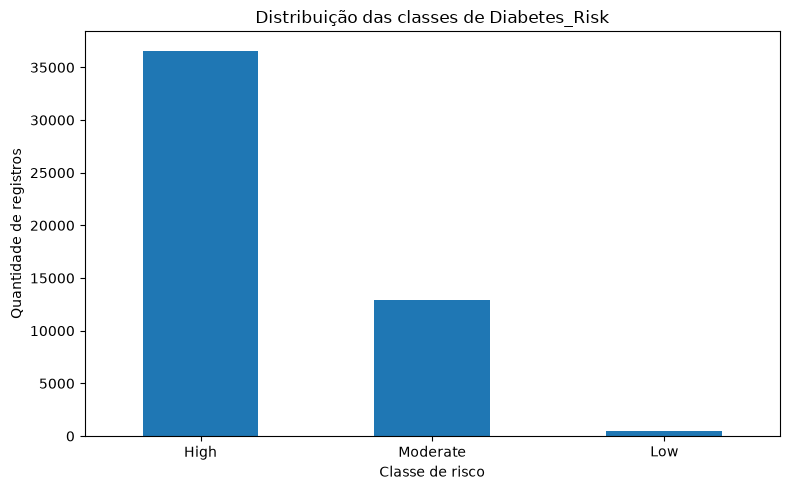

In [6]:
# Frequência absoluta e relativa
distribuicao = df_classification[target].value_counts()

resumo_target = pd.DataFrame({
    "Quantidade": distribuicao,
    "Percentual (%)": (
        distribuicao / len(df_classification) * 100
    ).round(2)
})

display(resumo_target)

# Gráfico da distribuição
distribuicao.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Distribuição das classes de Diabetes_Risk")
plt.xlabel("Classe de risco")
plt.ylabel("Quantidade de registros")
plt.tight_layout()
plt.show()


In [7]:
variaveis_numericas = [
    'Age',
    'Height_cm',
    'Weight_kg',
    'BMI',
    'Waist_Circumference_cm',
    'Blood_Glucose',
    'HbA1c',
    'Fasting_Blood_Sugar',
    'Insulin_Level',
    'Blood_Pressure_Systolic',
    'Blood_Pressure_Diastolic',
    'Total_Cholesterol',
    'HDL',
    'LDL',
    'Triglycerides',
    'Heart_Rate',
    'Exercise_Hours_Per_Week',
    'Daily_Walking_Minutes',
    'Sleep_Hours',
    'Daily_Water_Intake_L'
]

In [8]:

resumo_numericas = (
    df_classification
    .groupby(target)[variaveis_numericas]
    .agg(["mean", "median", "std", "count"])
    .round(2)
)

display(resumo_numericas.T)


Diabetes_Risk                    High     Low  Moderate
Age                  mean       56.50   38.94     46.97
                     median     58.00   35.00     43.00
                     std        20.62   17.09     20.50
                     count   36593.00  470.00  12937.00
Height_cm            mean      169.39  173.48    171.66
...                               ...     ...       ...
Sleep_Hours          count   36593.00  470.00  12937.00
Daily_Water_Intake_L mean        3.01    2.94      2.98
                     median      3.00    3.00      3.00
                     std         1.15    1.15      1.15
                     count   36593.00  470.00  12937.00

[80 rows x 3 columns]

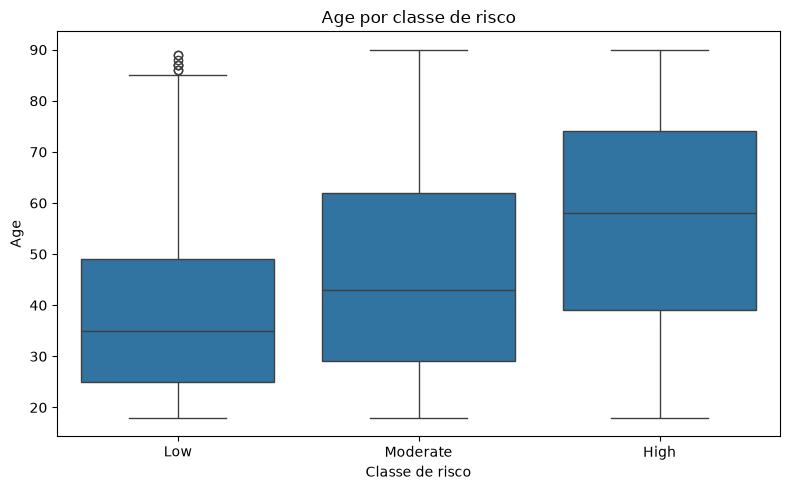

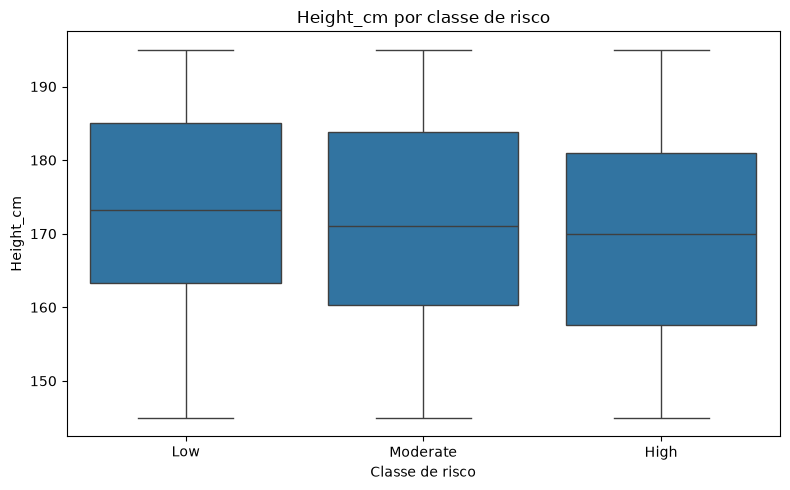

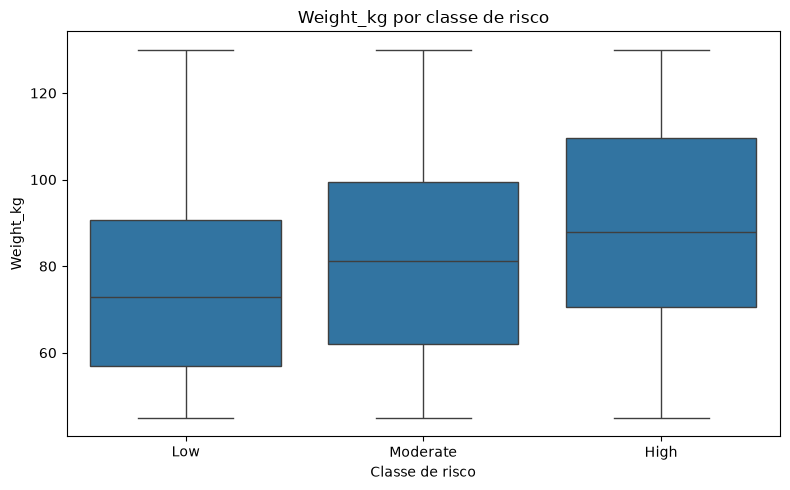

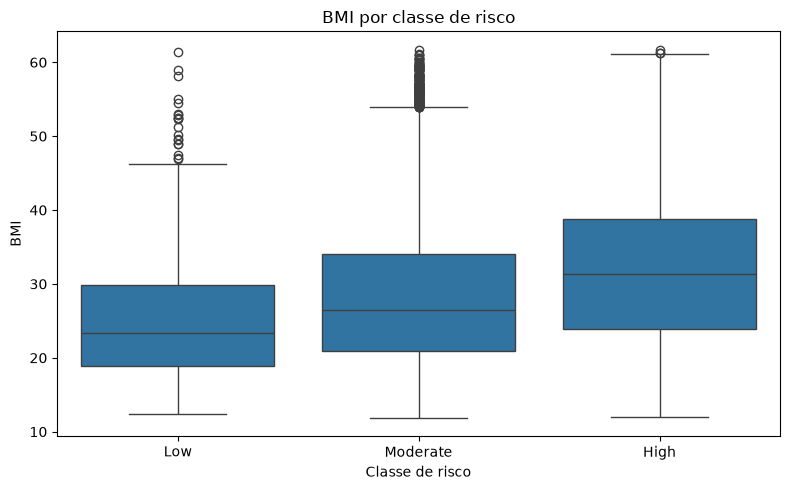

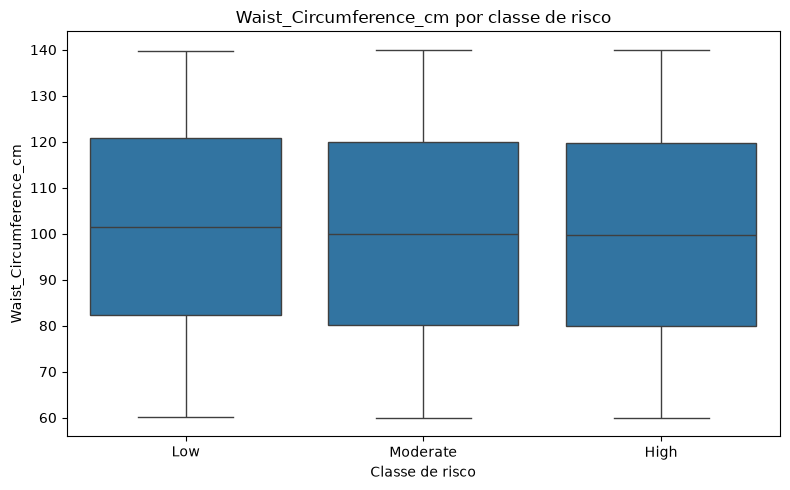

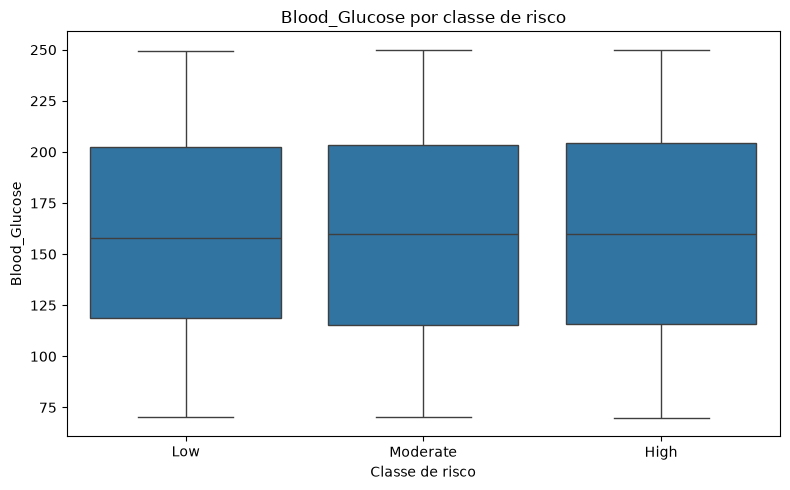

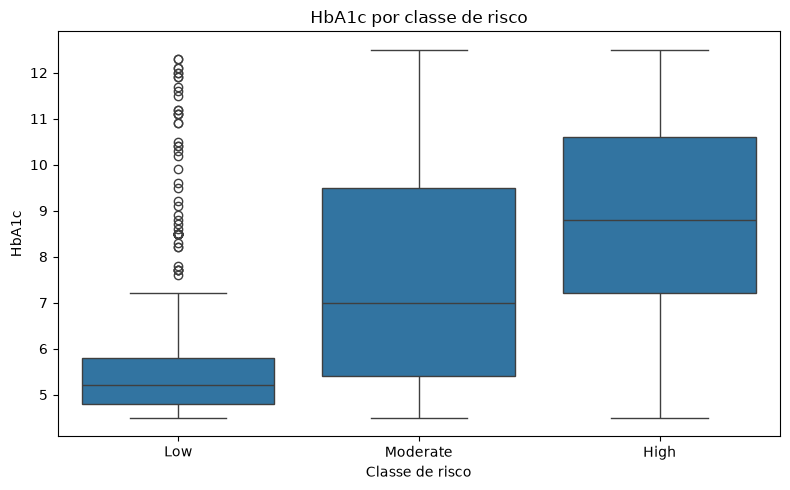

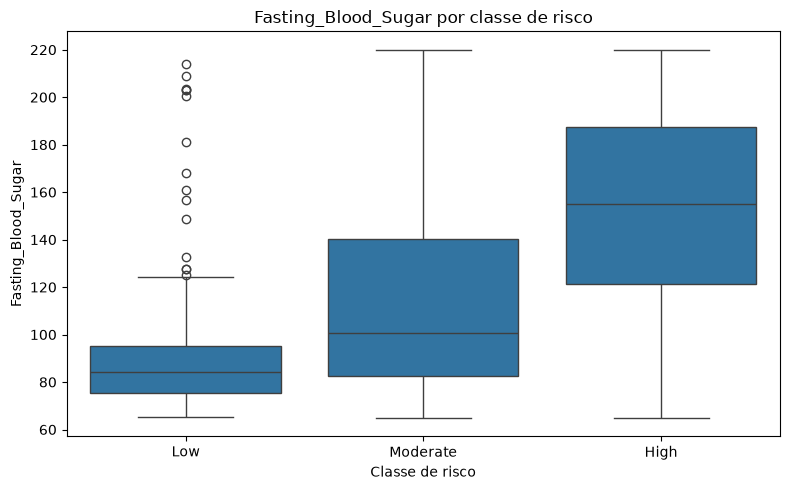

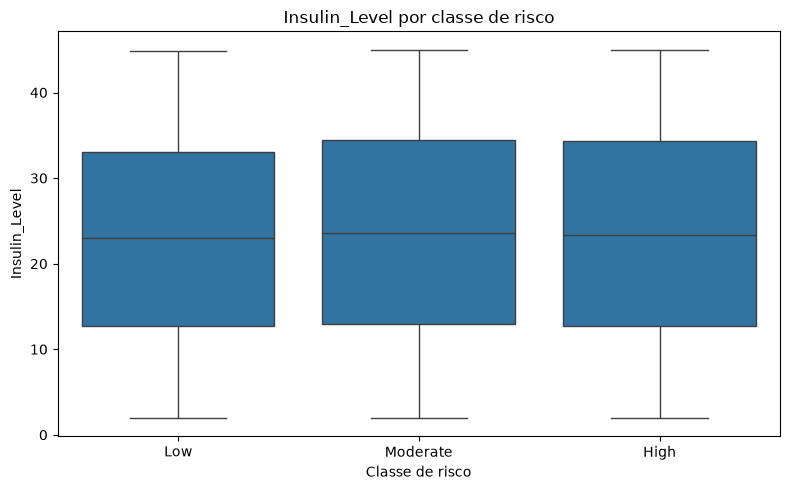

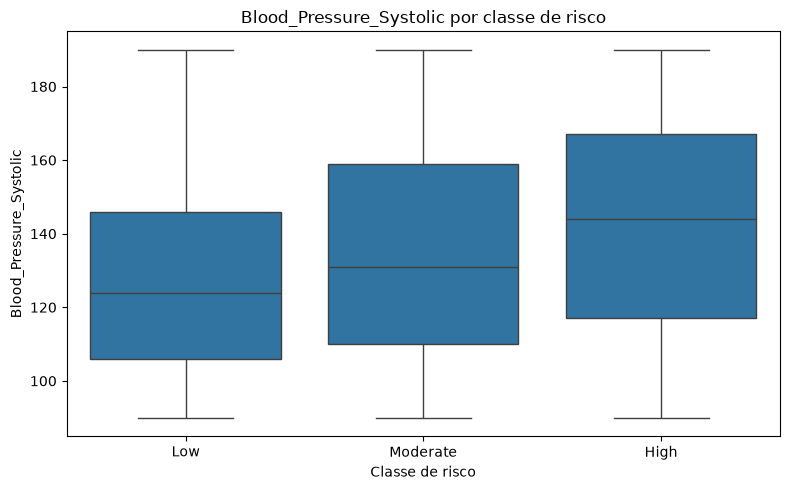

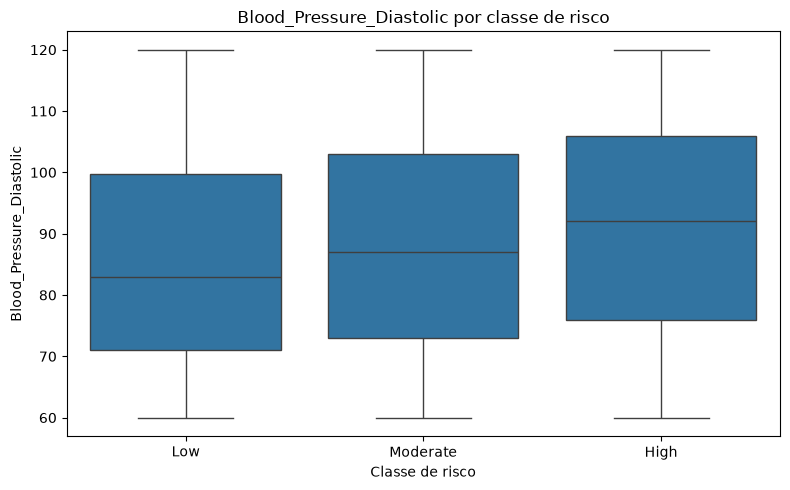

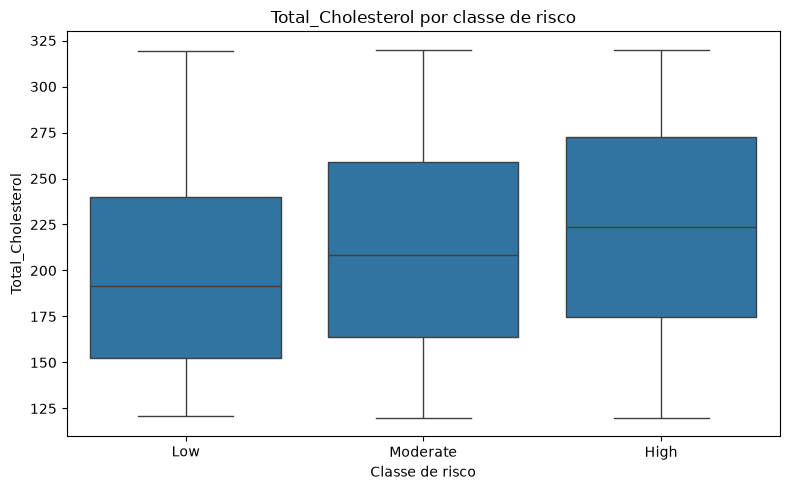

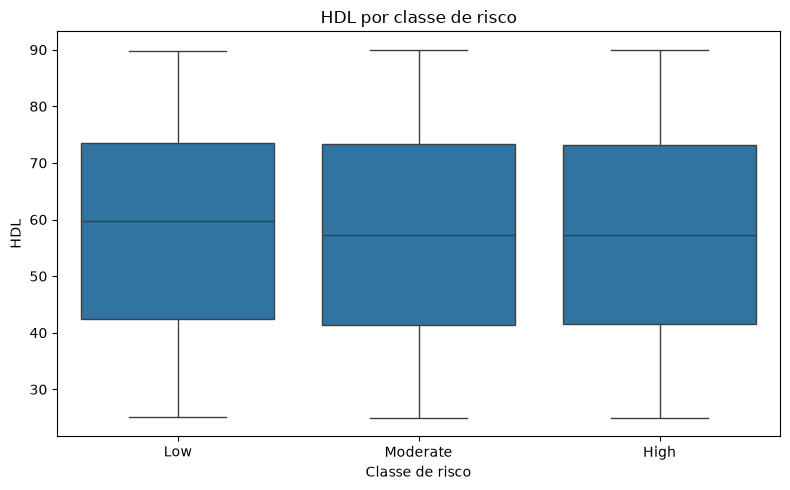

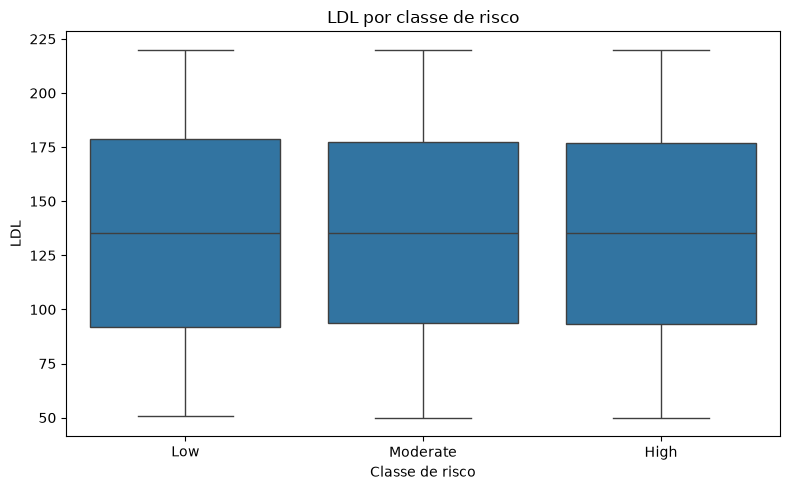

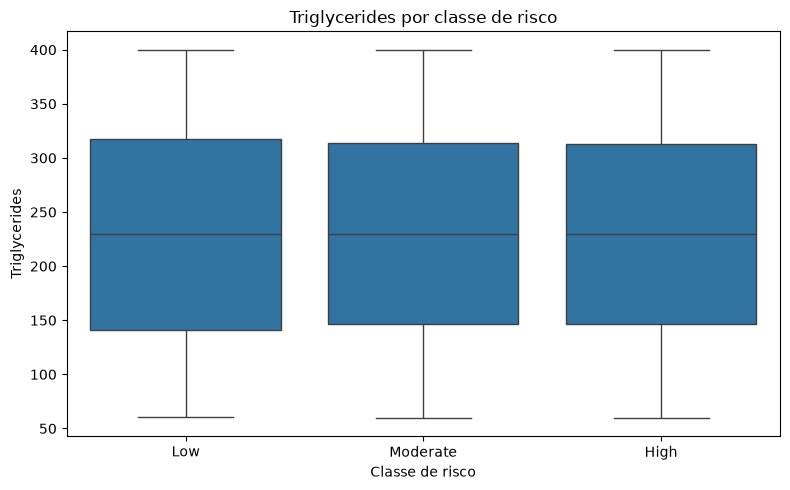

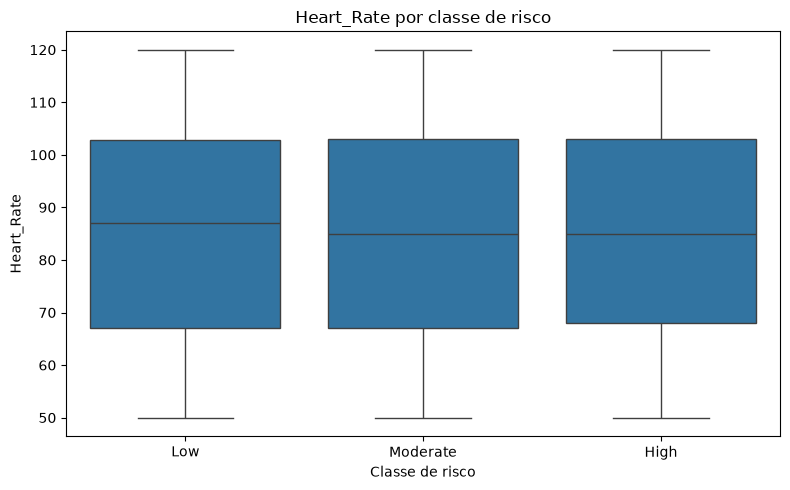

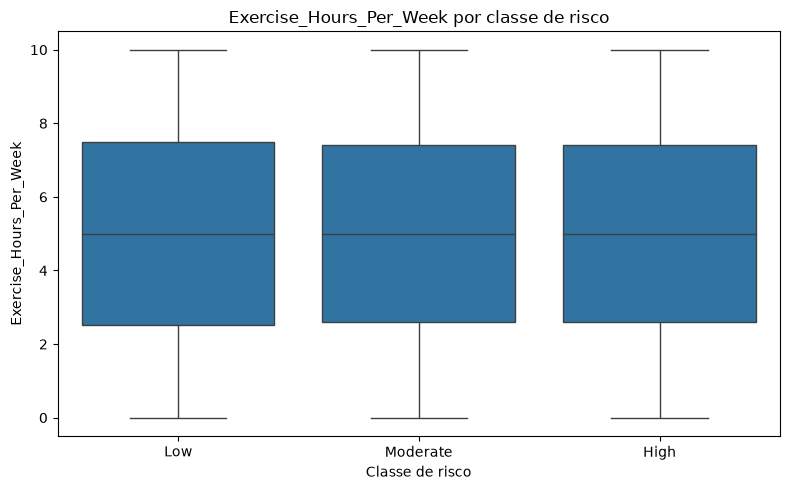

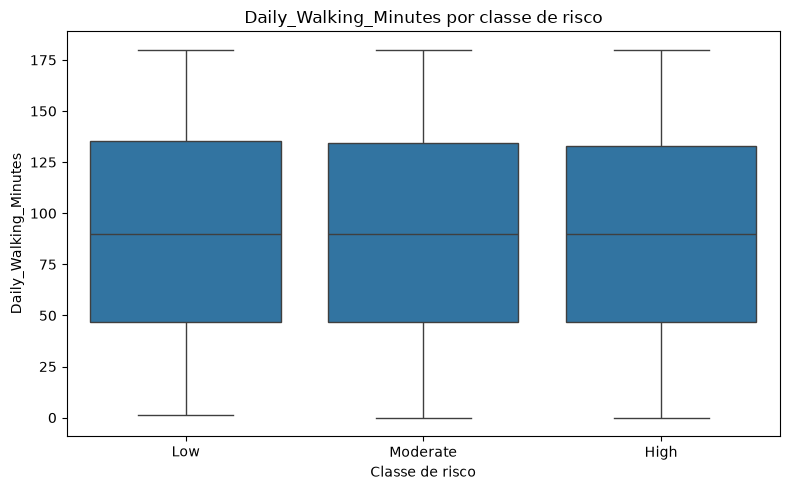

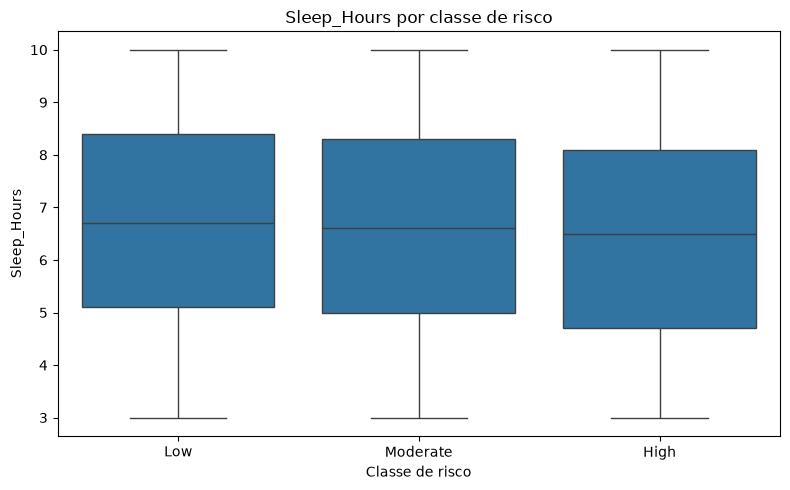

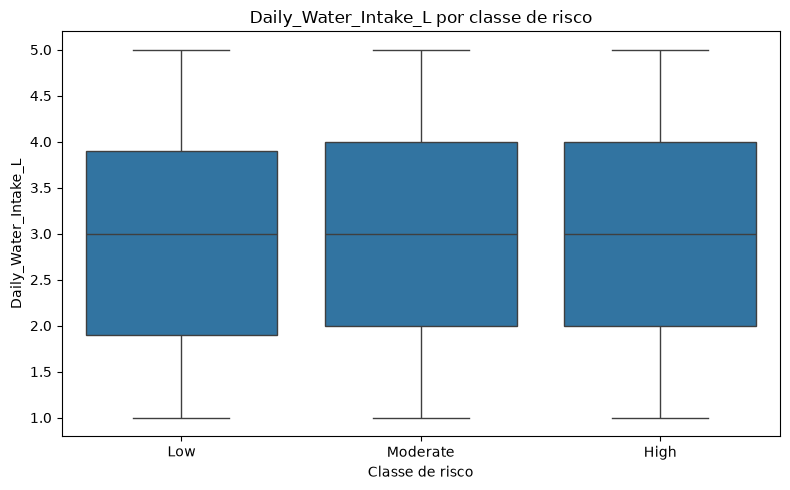

In [9]:
for coluna in variaveis_numericas:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df_classification,
        x=target,
        y=coluna,
        order=["Low", "Moderate", "High"]
    )

    plt.title(f"{coluna} por classe de risco")
    plt.xlabel("Classe de risco")
    plt.ylabel(coluna)
    plt.tight_layout()
    plt.show()


In [10]:
resultados = []

for coluna in variaveis_numericas:
    grupos = [
        df_classification.loc[
            df_classification[target] == classe, coluna
        ].dropna()
        for classe in ["Low", "Moderate", "High"]
    ]

    if all(len(grupo) > 0 for grupo in grupos):
        estatistica, p_valor = kruskal(*grupos)

        n = sum(len(grupo) for grupo in grupos)
        k = len(grupos)

        # Tamanho de efeito: epsilon ao quadrado
        epsilon2 = max(0, (estatistica - k + 1) / (n - k))

        resultados.append({
            "Feature": coluna,
            "Estatistica_H": estatistica,
            "p_valor": p_valor,
            "epsilon_quadrado": epsilon2
        })

resultados_numericos = pd.DataFrame(resultados)

if not resultados_numericos.empty:
    resultados_numericos["p_ajustado"] = multipletests(
        resultados_numericos["p_valor"],
        method="fdr_bh"
    )[1]

    resultados_numericos = resultados_numericos.sort_values(
        "epsilon_quadrado",
        ascending=False
    )

display(resultados_numericos.round(5))


,Feature,Estatistica_H,p_valor,epsilon_quadrado,p_ajustado
7,Fasting_Blood_Sugar,7242.77598,0.00000,0.14482,0.00000
6,HbA1c,3580.18379,0.00000,0.07157,0.00000
0,Age,2208.31013,0.00000,0.04413,0.00000
3,BMI,1456.58942,0.00000,0.02909,0.00000
2,Weight_kg,1026.80842,0.00000,0.02050,0.00000
9,Blood_Pressure_Systolic,717.82809,0.00000,0.01432,0.00000
11,Total_Cholesterol,431.09012,0.00000,0.00858,0.00000
1,Height_cm,276.13217,0.00000,0.00548,0.00000
10,Blood_Pressure_Diastolic,263.28356,0.00000,0.00523,0.00000
18,Sleep_Hours,122.57985,0.00000,0.00241,0.00000


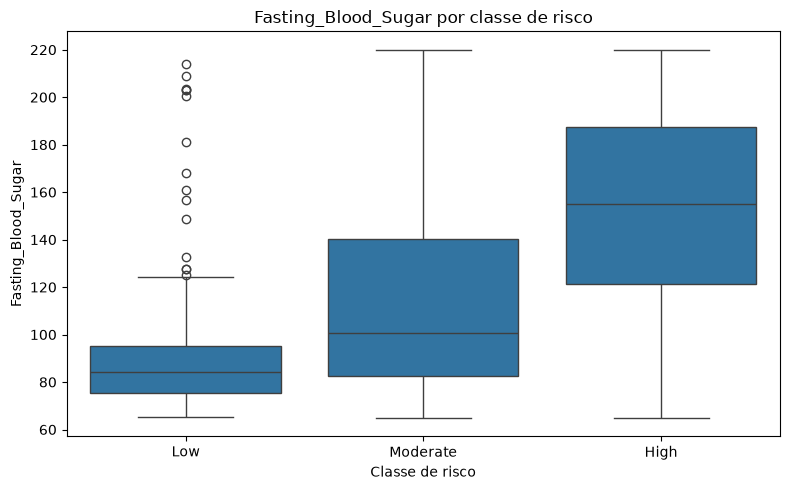

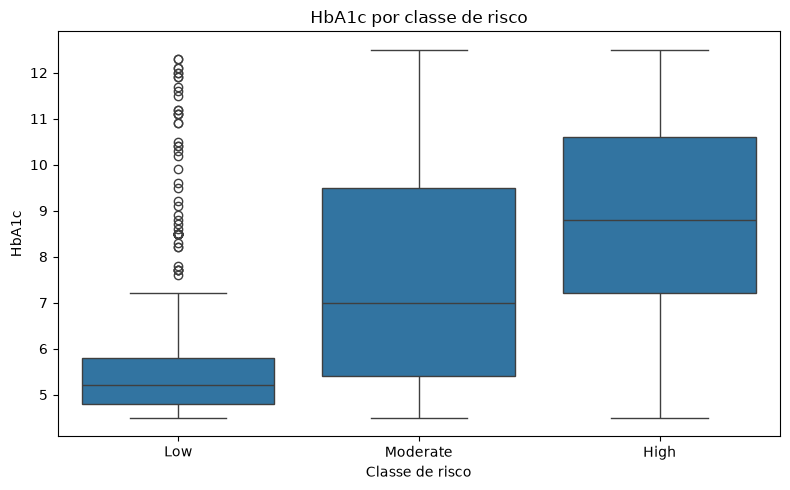

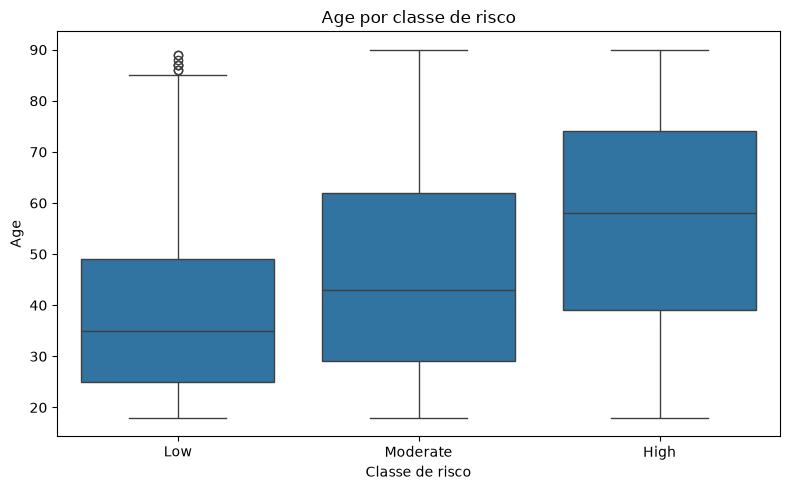

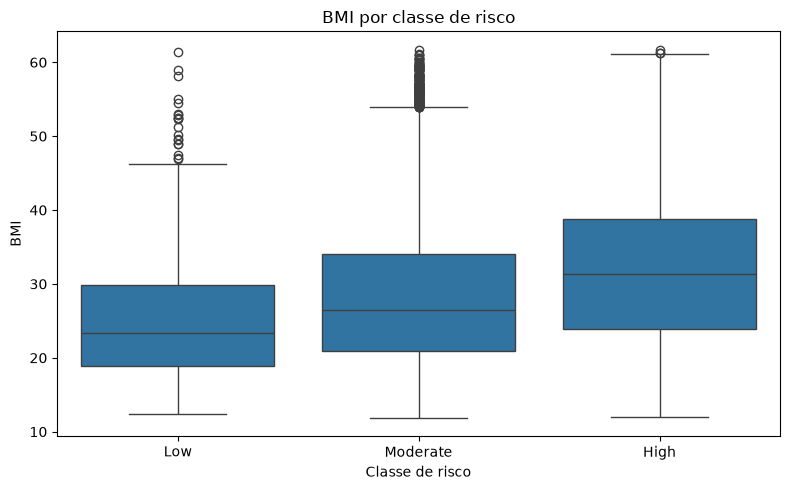

In [11]:
features_prioritarias = [
    "Fasting_Blood_Sugar",
    "HbA1c",
    "Age",
    "BMI"
]

ordem_classes = ["Low", "Moderate", "High"]

for coluna in features_prioritarias:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df_classification,
        x="Diabetes_Risk",
        y=coluna,
        order=ordem_classes
    )

    plt.title(f"{coluna} por classe de risco")
    plt.xlabel("Classe de risco")
    plt.ylabel(coluna)
    plt.tight_layout()
    plt.show()


In [12]:
# Identificar variáveis categóricas
colunas_categoricas = df_classification.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Quantidade de variáveis categóricas:", len(colunas_categoricas))
print("\nVariáveis encontradas:")

for coluna in colunas_categoricas:
    print(f"- {coluna}")

Quantidade de variáveis categóricas: 20

Variáveis encontradas:
- Gender
- Country
- Physical_Activity_Level
- Diet_Quality
- Sugar_Intake_Level
- Stress_Level
- Smoking_Status
- Alcohol_Consumption
- Family_History_Diabetes
- Hypertension
- Heart_Disease
- Fatty_Liver
- PCOS
- Medication_Adherence
- Work_Type
- Residence_Type
- AI_Health_Recommendation
- Doctor_Consultation_Needed
- Diabetes_Risk
- BMI_CATEGORY


C:\Users\lucas\AppData\Local\Temp\ipykernel_7880\586323116.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_categoricas = df_classification.select_dtypes(


In [13]:
colunas_excluir = [
    "Patient_ID",
    "Diabetes_Risk",
    "Diabetes_Risk_Score",
    "AI_Health_Recommendation",
    "Doctor_Consultation_Needed"
]

categoricas_analise = [
    coluna
    for coluna in colunas_categoricas
    if coluna not in colunas_excluir
]

print("Variáveis categóricas para análise:", len(categoricas_analise))

for coluna in categoricas_analise:
    print(f"- {coluna}")

Variáveis categóricas para análise: 17
- Gender
- Country
- Physical_Activity_Level
- Diet_Quality
- Sugar_Intake_Level
- Stress_Level
- Smoking_Status
- Alcohol_Consumption
- Family_History_Diabetes
- Hypertension
- Heart_Disease
- Fatty_Liver
- PCOS
- Medication_Adherence
- Work_Type
- Residence_Type
- BMI_CATEGORY


In [14]:
for coluna in categoricas_analise:
    print(f"\n{'=' * 60}")
    print(f"Variável: {coluna}")
    print("=" * 60)

    print("\nFrequências:")
    print(df_classification[coluna].value_counts(dropna=False))

    print("\nProporções (%):")
    print(
        (df_classification[coluna].value_counts(normalize=True, dropna=False) * 100)
        .round(2)
    )


Variável: Gender

Frequências:
Gender
Male      16718
Other     16677
Female    16605
Name: count, dtype: int64

Proporções (%):
Gender
Male      33.44
Other     33.35
Female    33.21
Name: proportion, dtype: float64

Variável: Country

Frequências:
Country
Malaysia          2083
Russia            2071
France            2068
China             2065
Canada            2050
United Kingdom    2037
Nigeria           2023
Indonesia         2011
Egypt             2010
Spain             2007
Mexico            1999
Germany           1999
South Korea       1997
South Africa      1996
Italy             1989
Turkey            1984
Japan             1983
India             1974
Bangladesh        1970
Brazil            1967
Pakistan          1959
Australia         1956
United States     1954
Argentina         1952
Saudi Arabia      1896
Name: count, dtype: int64

Proporções (%):
Country
Malaysia          4.17
Russia            4.14
France            4.14
China             4.13
Canada            4.10


In [15]:
resultados = []

for coluna in categoricas_analise:
    # Montar tabela de contingência
    tabela = pd.crosstab(
        df_classification[coluna],
        df_classification[target]
    )

    # Ignorar valores ausentes apenas nesta análise
    tabela = tabela.loc[tabela.sum(axis=1) > 0]

    if tabela.shape[0] < 2 or tabela.shape[1] < 2:
        continue

    # Teste qui-quadrado
    qui2, p_valor, graus_liberdade, frequencias_esperadas = (
        chi2_contingency(tabela)
    )

    # V de Cramér
    n = tabela.to_numpy().sum()
    menor_dimensao = min(tabela.shape[0] - 1, tabela.shape[1] - 1)
    v_cramer = np.sqrt(qui2 / (n * menor_dimensao))

    # Verificar frequências esperadas pequenas
    percentual_esperadas_baixas = (
        (frequencias_esperadas < 5).sum()
        / frequencias_esperadas.size
        * 100
    )

    resultados.append({
        "Feature": coluna,
        "Qui_quadrado": qui2,
        "Graus_liberdade": graus_liberdade,
        "p_valor": p_valor,
        "V_Cramer": v_cramer,
        "Esperadas_abaixo_5_pct": percentual_esperadas_baixas
    })

# Organizar resultados
df_resultados_cat = pd.DataFrame(resultados)

# Corrigir os p-valores para múltiplos testes
if not df_resultados_cat.empty:
    df_resultados_cat["p_ajustado"] = multipletests(
        df_resultados_cat["p_valor"],
        method="fdr_bh"
    )[1]

    df_resultados_cat = df_resultados_cat.sort_values(
        "V_Cramer",
        ascending=False
    ).reset_index(drop=True)

    display(df_resultados_cat.round(5))

,Feature,Qui_quadrado,Graus_liberdade,p_valor,V_Cramer,Esperadas_abaixo_5_pct,p_ajustado
0,Family_History_Diabetes,2439.77243,2,0.00000,0.22090,0.00000,0.00000
1,Hypertension,949.13833,2,0.00000,0.13778,0.00000,0.00000
2,BMI_CATEGORY,1580.51755,6,0.00000,0.12572,0.00000,0.00000
3,PCOS,689.45802,2,0.00000,0.11743,0.00000,0.00000
4,Heart_Disease,658.37990,2,0.00000,0.11475,0.00000,0.00000
5,Fatty_Liver,385.36635,2,0.00000,0.08779,0.00000,0.00000
6,Physical_Activity_Level,761.39719,6,0.00000,0.08726,8.33333,0.00000
7,Diet_Quality,739.18595,4,0.00000,0.08598,0.00000,0.00000
8,Smoking_Status,543.08291,4,0.00000,0.07369,0.00000,0.00000
9,Stress_Level,515.59405,4,0.00000,0.07180,0.00000,0.00000


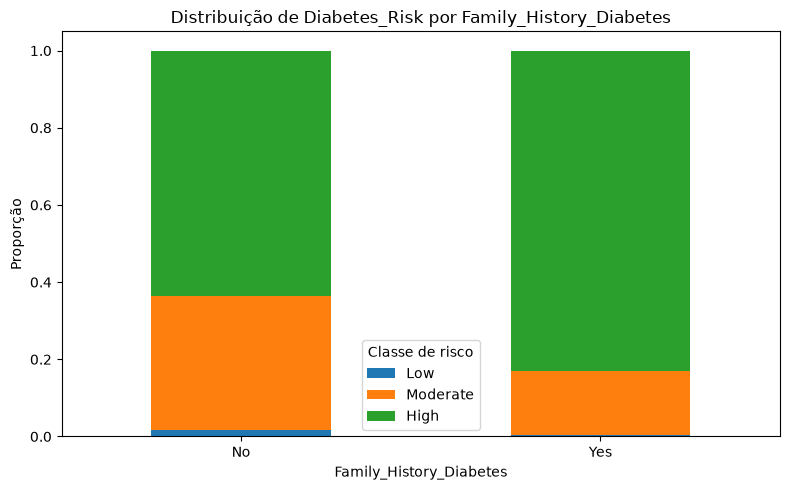

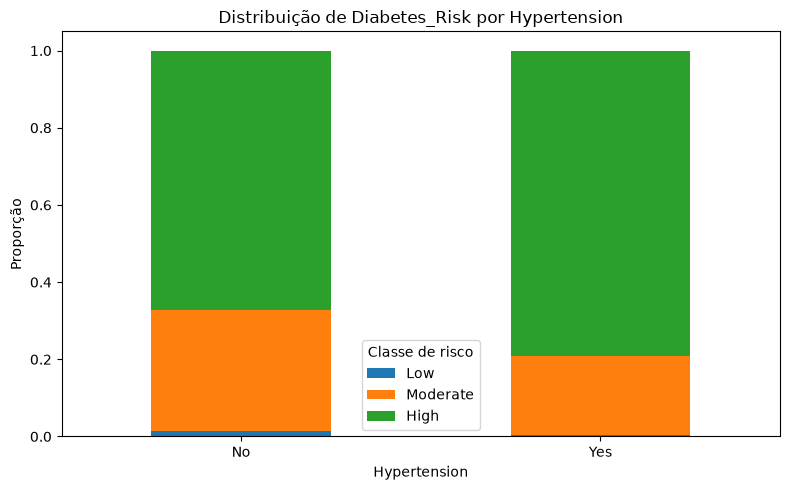

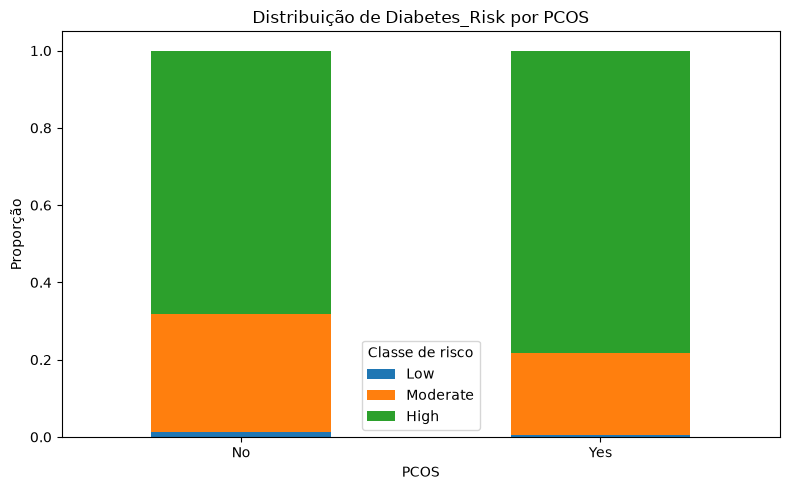

In [16]:
import matplotlib.pyplot as plt
import pandas as pd

features_categoricas = [
    "Family_History_Diabetes",
    "Hypertension",
    "PCOS"
]

ordem_classes = ["Low", "Moderate", "High"]

for coluna in features_categoricas:
    tabela = pd.crosstab(
        df_classification[coluna],
        df_classification["Diabetes_Risk"],
        normalize="index"
    ).reindex(columns=ordem_classes)

    ax = tabela.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 5)
    )

    ax.set_title(f"Distribuição de Diabetes_Risk por {coluna}")
    ax.set_xlabel(coluna)
    ax.set_ylabel("Proporção")
    ax.legend(title="Classe de risco")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

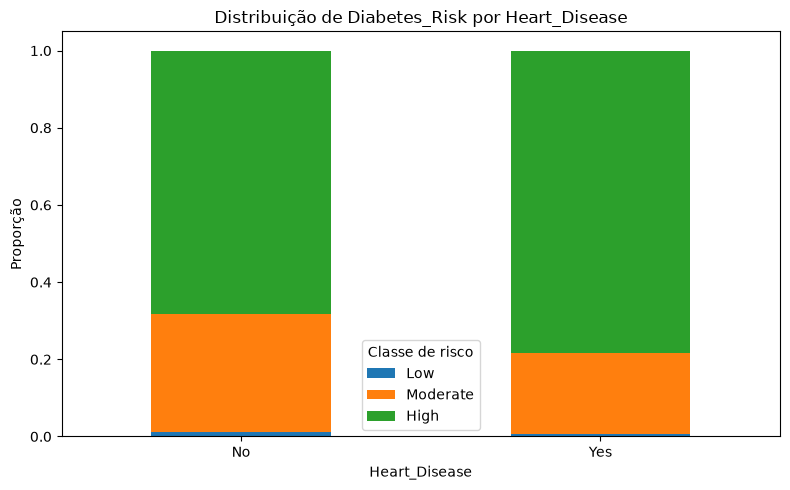

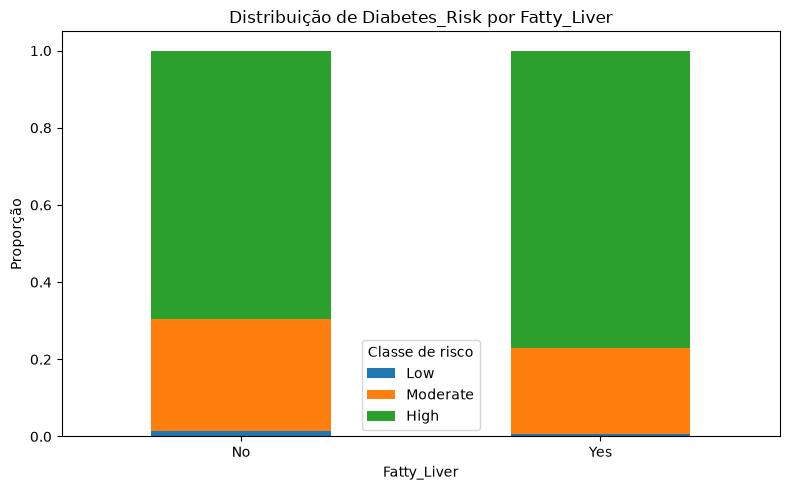

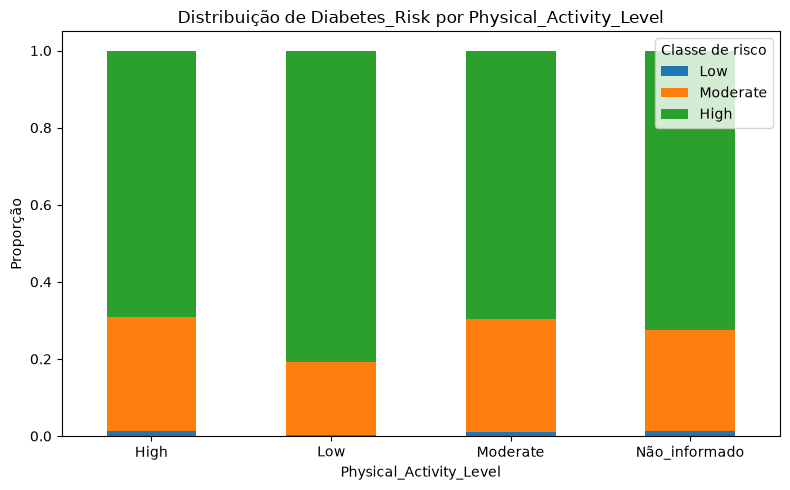

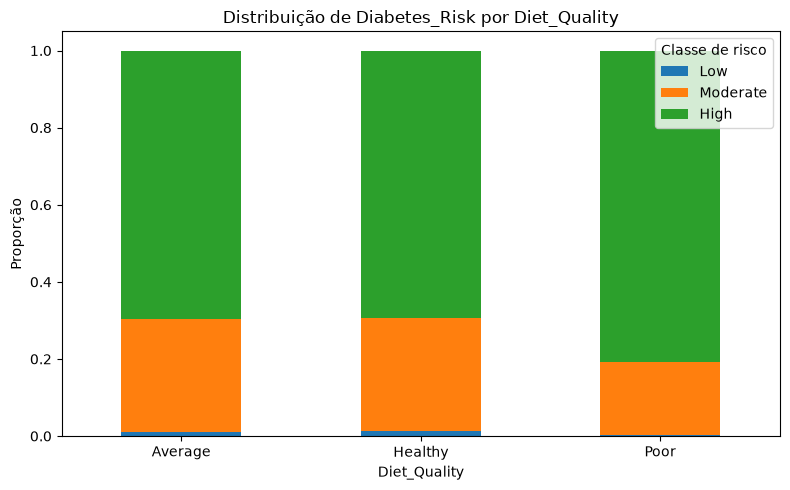

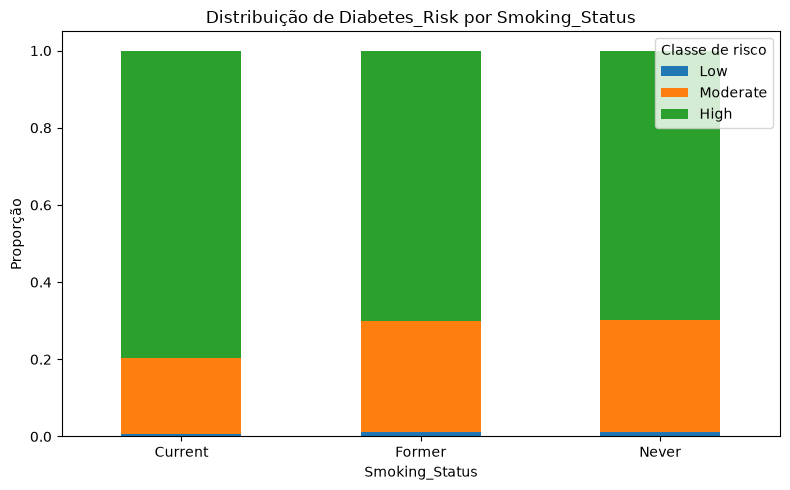

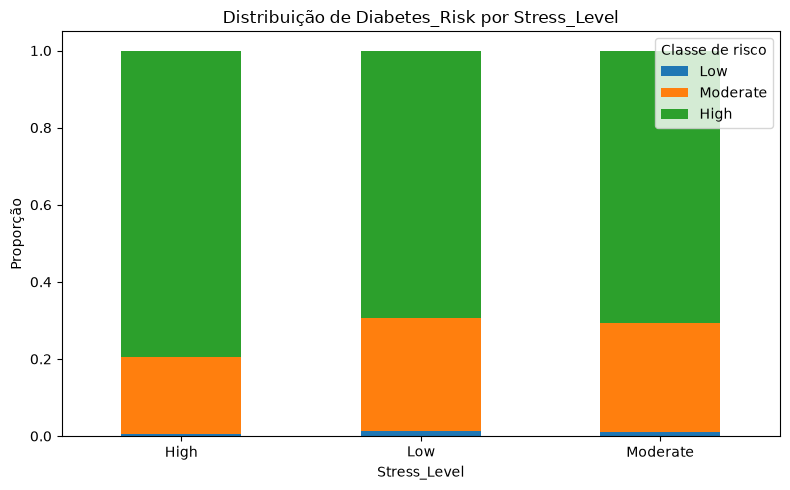

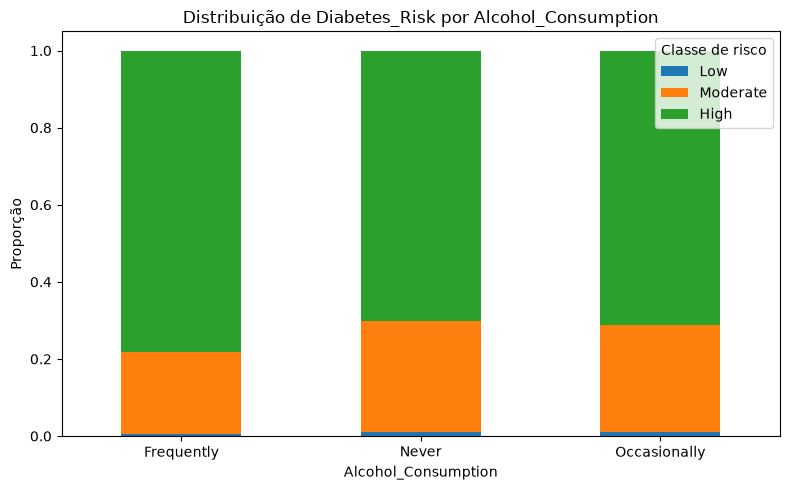

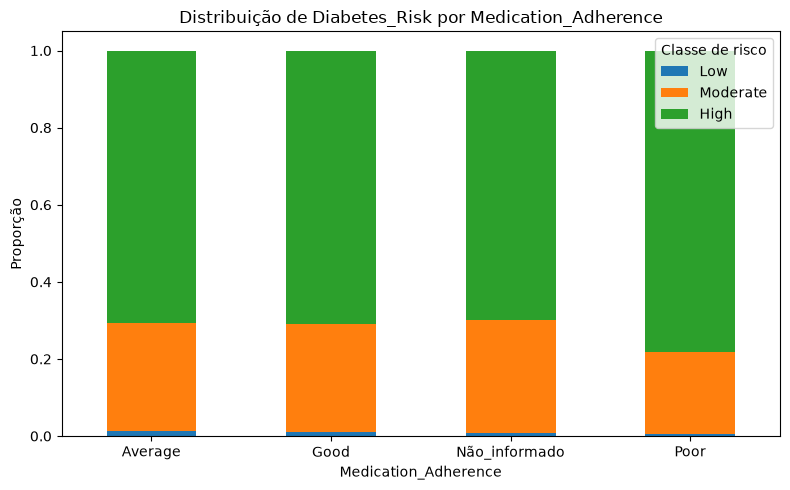

In [17]:
features_categoricas = [
    "Heart_Disease",
    "Fatty_Liver",
    "Physical_Activity_Level",
    "Diet_Quality",
    "Smoking_Status",
    "Stress_Level",
    "Alcohol_Consumption",
    "Medication_Adherence"
]

ordem_classes = ["Low", "Moderate", "High"]

for coluna in features_categoricas:
    tabela = pd.crosstab(
        df_classification[coluna],
        df_classification["Diabetes_Risk"],
        normalize="index"
    ).reindex(columns=ordem_classes, fill_value=0)

    ax = tabela.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 5)
    )

    ax.set_title(f"Distribuição de Diabetes_Risk por {coluna}")
    ax.set_xlabel(coluna)
    ax.set_ylabel("Proporção")
    ax.legend(title="Classe de risco")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [18]:
# Features selecionadas
features_classification = [
    "Fasting_Blood_Sugar_Scaled",
    "HbA1c_Scaled",
    "Age_Scaled",
    "BMI_Scaled",
    "Family_History_Diabetes_Encoded",
    "Hypertension_Encoded",
    "Diet_Quality_Encoded",
    "PCOS_Encoded",
    "Heart_Disease_Encoded"
]

# Target
target = "Diabetes_Risk"

# Selecionar somente as features e o target
df_classification = df[features_classification + [target]].copy()

# Conferir o resultado
display(df_classification.head())
print("Dimensões:", df_classification.shape)
print("\nTipos de dados:")

,Fasting_Blood_Sugar_Scaled,HbA1c_Scaled,Age_Scaled,BMI_Scaled,Family_History_Diabetes_Encoded,Hypertension_Encoded,Diet_Quality_Encoded,PCOS_Encoded,Heart_Disease_Encoded,Diabetes_Risk
0,0.154264,0.842947,-1.040320,-1.081056,1,0,2,0,1,Moderate
1,1.268823,1.239842,-0.564688,1.455390,1,0,2,1,1,High
2,1.723151,-0.965130,1.670782,0.677935,1,0,1,0,0,High
3,1.680627,-0.480037,1.575655,-0.449374,1,1,1,0,0,High
4,0.243786,1.548538,-1.278136,1.018072,0,1,0,1,1,High


Dimensões: (50000, 10)

Tipos de dados:


In [19]:
df_classification.to_csv(
    "../data/processed/dataset_classification.csv",
    index=False,
    encoding="utf-8"
)

print("Dataset de classificação salvo com sucesso!")

Dataset de classificação salvo com sucesso!
